# IND320 Compulsory Assignment 2

This notebook documents the second compulsory assignment in IND320. It extends the reservoir dashboard from Part 1 by replacing the local CSV source with the NVE Magasinstatistikk API and by adding a pipeline for ENTSO-E cross-border physical flow data using Cassandra, Spark and MongoDB.

## Project Links

- GitHub repository: https://github.com/VasiliiAnderson/ind320-project
- Streamlit application: https://vasilii-ind320.streamlit.app/

## 1. Setup and Imports

Secrets are stored locally in `.env` and are excluded from Git. The notebook expects `MONGODB_URI` and `ENTSOE_TOKEN`. On Windows, Spark also requires a working local Hadoop setup. Adjust the path below if Hadoop is installed elsewhere.

In [1]:
import os
import time
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from cassandra.cluster import Cluster
from dotenv import load_dotenv
from pymongo import MongoClient

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / ".env").exists() and (PROJECT_ROOT.parent / ".env").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(PROJECT_ROOT / ".env")

if os.name == "nt" and not os.environ.get("HADOOP_HOME"):
    os.environ["HADOOP_HOME"] = r"C:\Hadoop\hadoop-3.3.5"
    os.environ["PATH"] = os.path.join(os.environ["HADOOP_HOME"], "bin") + os.pathsep + os.environ["PATH"]

print("Project root:", PROJECT_ROOT)
print("HADOOP_HOME:", os.environ.get("HADOOP_HOME"))
print("MongoDB URI available:", bool(os.getenv("MONGODB_URI")))
print("ENTSO-E token available:", bool(os.getenv("ENTSOE_TOKEN")))

Project root: c:\dev\IND320\project
HADOOP_HOME: C:\Hadoop\hadoop-3.3.5
MongoDB URI available: True
ENTSO-E token available: True


## 2. NVE Magasinstatistikk API

The reservoir statistics used in Compulsory Assignment 1 were loaded from a local CSV file. In Part 2, the data are retrieved directly from the NVE Magasinstatistikk API.

### 2.1 Retrieve Area Information

In [2]:
NVE_BASE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

areas_response = requests.get(f"{NVE_BASE_URL}/HentOmråder", timeout=30)
areas_response.raise_for_status()
areas = areas_response.json()
areas

[{'land': [{'navn': 'Norge',
    'navn_langt': 'Norge',
    'beskrivelse': 'Hele landet',
    'omrType': 'NO',
    'omrnr': 0}],
  'elspot': [{'navn': 'NO 1',
    'navn_langt': 'Elspotområde 1',
    'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).',
    'omrType': 'EL',
    'omrnr': 1},
   {'navn': 'NO 2',
    'navn_langt': 'Elspotområde 2',
    'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.',
    'omrType': 'EL',
    'omrnr': 2},
   {'navn': 'NO 3',
    'navn_langt': 'Elspotområde 3',
    'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.',
    'omrType': 'EL',
    'omrnr': 3},
   {'navn': 'NO 4',
    'navn_langt': 'Elspotområde 4',
    'beskrivelse': 'Nord-Norge. Omfatter resten av

### 2.2 Retrieve Reservoir Data

In [3]:
reservoir_response = requests.get(f"{NVE_BASE_URL}/HentOffentligData", timeout=30)
reservoir_response.raise_for_status()
reservoir_df = pd.DataFrame(reservoir_response.json())

print("Rows:", len(reservoir_df))
reservoir_df.head()

Rows: 14922


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


### 2.3 Prepare the Data

In [4]:
reservoir_df = reservoir_df.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_twh",
    "fylling_TWh": "stored_energy_twh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "previous_week_fill_level",
    "endring_fyllingsgrad": "change_in_fill_level",
})

reservoir_df["date"] = pd.to_datetime(reservoir_df["date"])
reservoir_df["next_publication_date"] = reservoir_df["next_publication_date"].replace("0001-01-01T00:00:00", pd.NA)
reservoir_df["next_publication_date"] = pd.to_datetime(reservoir_df["next_publication_date"], errors="coerce")
reservoir_df = reservoir_df.sort_values(["date", "area_type", "area_number"]).reset_index(drop=True)

print("Area types and associated area numbers:")
display(reservoir_df.groupby("area_type")["area_number"].unique())
reservoir_df.info()

Area types and associated area numbers:


area_type
EL      [1, 2, 3, 4, 5]
NO                  [0]
VASS          [1, 2, 3]
Name: area_number, dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 14922 entries, 0 to 14921
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      14922 non-null  datetime64[us]
 1   area_type                 14922 non-null  str           
 2   area_number               14922 non-null  int64         
 3   iso_year                  14922 non-null  int64         
 4   iso_week                  14922 non-null  int64         
 5   fill_level                14922 non-null  float64       
 6   capacity_twh              14922 non-null  float64       
 7   stored_energy_twh         14922 non-null  float64       
 8   next_publication_date     3600 non-null   datetime64[us]
 9   previous_week_fill_level  14922 non-null  float64       
 10  change_in_fill_level      14922 non-null  float64       
dtypes: datetime64[us](2), float64(5), int64(3), str(1)
memory usage: 1.3 MB


### 2.4 Reservoir Visualisation

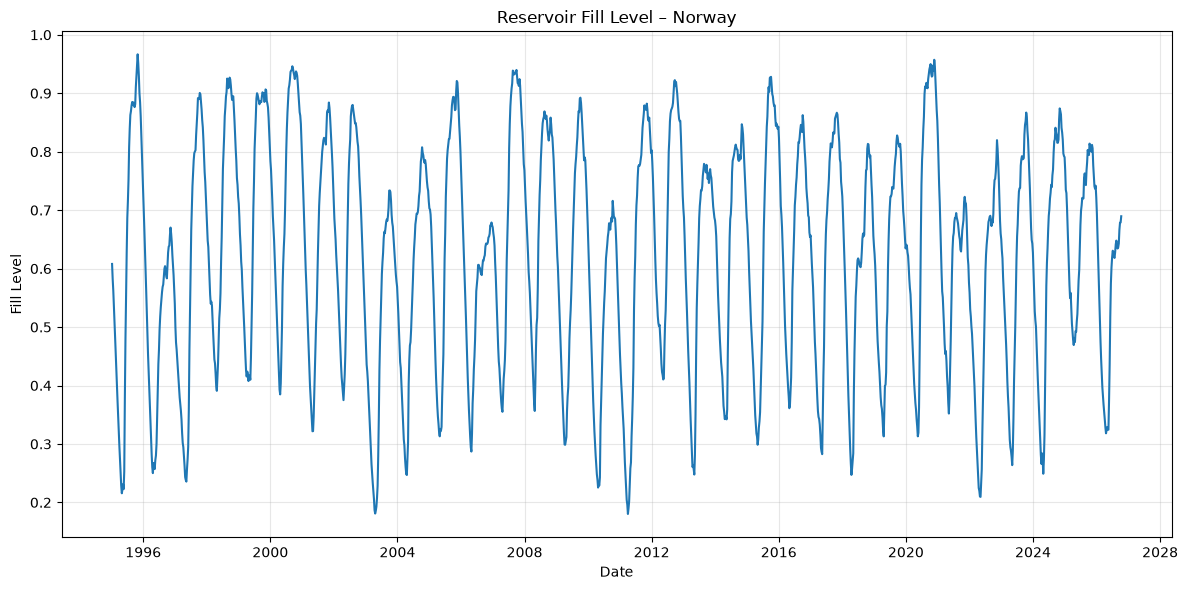

In [5]:
national_data = reservoir_df[(reservoir_df["area_type"] == "NO") & (reservoir_df["area_number"] == 0)].sort_values("date").copy()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(national_data["date"], national_data["fill_level"])
ax.set_title("Reservoir Fill Level – Norway")
ax.set_xlabel("Date")
ax.set_ylabel("Fill Level")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 3. Cassandra and Spark

Cassandra is run locally in Docker and exposed on port `9042`. This section creates a small test table and verifies that Spark can read from Cassandra.

### 3.1 Create a Cassandra Connection Test

In [6]:
cluster = Cluster(["localhost"], port=9042)
cassandra_session = cluster.connect()

cassandra_session.execute("""
CREATE KEYSPACE IF NOT EXISTS ind320_test
WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")

cassandra_session.execute("""
CREATE TABLE IF NOT EXISTS ind320_test.spark_test (
    id int PRIMARY KEY,
    value text
)
""")

cassandra_session.execute("""
INSERT INTO ind320_test.spark_test (id, value)
VALUES (1, 'Spark-Cassandra connection works')
""")

print("Cassandra test table is ready.")

Cassandra test table is ready.


### 3.2 Configure Spark

In [7]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("IND320SparkCassandra")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.extensions", "com.datastax.spark.connector.CassandraSparkExtensions")
    .config("spark.sql.catalog.mycatalog", "com.datastax.spark.connector.datasource.CassandraCatalog")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.9


### 3.3 Verify the Spark–Cassandra Connection

In [8]:
spark_cassandra_test = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320_test", table="spark_test")
    .load()
)

spark_cassandra_test.show(truncate=False)

cassandra_session.shutdown()
cluster.shutdown()

+---+--------------------------------+
|id |value                           |
+---+--------------------------------+
|1  |Spark-Cassandra connection works|
+---+--------------------------------+



## 4. ENTSO-E API

Cross-border physical flow data are retrieved from the ENTSO-E Transparency Platform Web API. The security token is read from `.env` and is never printed or stored in the notebook.

### 4.1 Authentication and API Test

In [9]:
ENTSOE_TOKEN = os.getenv("ENTSOE_TOKEN")
ENTSOE_API_URL = "https://web-api.tp.entsoe.eu/api"

if not ENTSOE_TOKEN:
    raise RuntimeError("ENTSOE_TOKEN is missing. Add it to the local .env file before continuing.")

NO2 = "10YNO-2--------T"
DE_LU = "10Y1001A1001A82H"

test_params = {
    "securityToken": ENTSOE_TOKEN,
    "documentType": "A11",
    "out_Domain": NO2,
    "in_Domain": DE_LU,
    "periodStart": "202610010000",
    "periodEnd": "202610020000",
}

entsoe_test_response = requests.get(ENTSOE_API_URL, params=test_params, timeout=60)
entsoe_test_response.raise_for_status()

print("Status code:", entsoe_test_response.status_code)
print("Content type:", entsoe_test_response.headers.get("Content-Type"))
print(entsoe_test_response.text[:120])

Status code: 200
Content type: text/xml
<?xml version="1.0" encoding="utf-8"?>
<Publication_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-3:publicationdoc


### 4.2 Parse Physical Flow Data

In [10]:
def parse_entsoe_physical_flow(xml_text, connection, direction):
    """Parse ENTSO-E cross-border physical flow XML into a pandas DataFrame."""
    root = ET.fromstring(xml_text)

    if root.tag.endswith("Acknowledgement_MarketDocument"):
        reason = root.findtext(".//{*}text") or "Unknown ENTSO-E API error"
        raise RuntimeError(reason)

    namespace = {"ns": root.tag.split("}")[0].strip("{")}
    rows = []

    for time_series in root.findall("ns:TimeSeries", namespace):
        out_domain = time_series.findtext("ns:out_Domain.mRID", namespaces=namespace)
        in_domain = time_series.findtext("ns:in_Domain.mRID", namespaces=namespace)

        for period in time_series.findall("ns:Period", namespace):
            start = pd.Timestamp(period.findtext("ns:timeInterval/ns:start", namespaces=namespace))
            resolution = period.findtext("ns:resolution", namespaces=namespace)

            if resolution.startswith("PT") and resolution.endswith("M"):
                minutes = int(resolution.removeprefix("PT").removesuffix("M"))
            elif resolution.startswith("PT") and resolution.endswith("H"):
                minutes = int(resolution.removeprefix("PT").removesuffix("H")) * 60
            else:
                raise ValueError(f"Unsupported ENTSO-E resolution: {resolution}")

            for point in period.findall("ns:Point", namespace):
                position = int(point.findtext("ns:position", namespaces=namespace))
                quantity_mw = float(point.findtext("ns:quantity", namespaces=namespace))
                timestamp = start + pd.Timedelta(minutes=(position - 1) * minutes)

                rows.append({
                    "timestamp": timestamp,
                    "connection": connection,
                    "direction": direction,
                    "out_domain": out_domain,
                    "in_domain": in_domain,
                    "quantity_mw": quantity_mw,
                    "interval_minutes": minutes,
                    "energy_mwh": quantity_mw * minutes / 60,
                })

    return pd.DataFrame(rows)

In [11]:
test_flow_df = parse_entsoe_physical_flow(
    entsoe_test_response.text,
    connection="NO2-DE_LU",
    direction="Export",
)

test_flow_df[["timestamp", "connection", "direction", "quantity_mw", "energy_mwh"]].head(10)

,timestamp,connection,direction,quantity_mw,energy_mwh
0,2026-10-01 00:00:00+00:00,NO2-DE_LU,Export,1047.52,261.88
1,2026-10-01 00:15:00+00:00,NO2-DE_LU,Export,1043.84,260.96
2,2026-10-01 00:30:00+00:00,NO2-DE_LU,Export,1080.80,270.20
3,2026-10-01 00:45:00+00:00,NO2-DE_LU,Export,1114.56,278.64
4,2026-10-01 01:00:00+00:00,NO2-DE_LU,Export,1226.08,306.52
5,2026-10-01 01:15:00+00:00,NO2-DE_LU,Export,1245.76,311.44
6,2026-10-01 01:30:00+00:00,NO2-DE_LU,Export,1238.40,309.60
7,2026-10-01 01:45:00+00:00,NO2-DE_LU,Export,1289.92,322.48
8,2026-10-01 02:00:00+00:00,NO2-DE_LU,Export,1301.92,325.48
9,2026-10-01 02:15:00+00:00,NO2-DE_LU,Export,1296.64,324.16


### 4.3 Reusable API Function

In [12]:
def fetch_entsoe_flow(out_domain, in_domain, period_start, period_end, connection, direction):
    """Download and parse one ENTSO-E physical-flow request."""
    params = {
        "securityToken": ENTSOE_TOKEN,
        "documentType": "A11",
        "out_Domain": out_domain,
        "in_Domain": in_domain,
        "periodStart": period_start.strftime("%Y%m%d%H%M"),
        "periodEnd": period_end.strftime("%Y%m%d%H%M"),
    }

    response = requests.get(ENTSOE_API_URL, params=params, timeout=60)
    response.raise_for_status()

    return parse_entsoe_physical_flow(
        response.text,
        connection=connection,
        direction=direction,
    )

### 4.4 Cross-Border Connections

In [13]:
CONNECTIONS = {
    "NO1-SE3": {"norway": "10YNO-1--------2", "foreign": "10Y1001A1001A46L"},
    "NO2-DK1": {"norway": "10YNO-2--------T", "foreign": "10YDK-1--------W"},
    "NO2-DE_LU": {"norway": "10YNO-2--------T", "foreign": "10Y1001A1001A82H"},
    "NO2-NL": {"norway": "10YNO-2--------T", "foreign": "10YNL----------L"},
    "NO2-GB": {"norway": "10YNO-2--------T", "foreign": "10YGB----------A"},
    "NO3-SE2": {"norway": "10YNO-3--------J", "foreign": "10Y1001A1001A45N"},
    "NO4-SE1": {"norway": "10YNO-4--------9", "foreign": "10Y1001A1001A44P"},
    "NO4-SE2": {"norway": "10YNO-4--------9", "foreign": "10Y1001A1001A45N"},
    "NO4-FI": {"norway": "10YNO-4--------9", "foreign": "10YFI-1--------U"},
}

CONNECTIONS

{'NO1-SE3': {'norway': '10YNO-1--------2', 'foreign': '10Y1001A1001A46L'},
 'NO2-DK1': {'norway': '10YNO-2--------T', 'foreign': '10YDK-1--------W'},
 'NO2-DE_LU': {'norway': '10YNO-2--------T', 'foreign': '10Y1001A1001A82H'},
 'NO2-NL': {'norway': '10YNO-2--------T', 'foreign': '10YNL----------L'},
 'NO2-GB': {'norway': '10YNO-2--------T', 'foreign': '10YGB----------A'},
 'NO3-SE2': {'norway': '10YNO-3--------J', 'foreign': '10Y1001A1001A45N'},
 'NO4-SE1': {'norway': '10YNO-4--------9', 'foreign': '10Y1001A1001A44P'},
 'NO4-SE2': {'norway': '10YNO-4--------9', 'foreign': '10Y1001A1001A45N'},
 'NO4-FI': {'norway': '10YNO-4--------9', 'foreign': '10YFI-1--------U'}}

### 4.5 Retrieve the Last Two Years

In [14]:
def fetch_connection_two_years(connection_name, connection_info, start_date, end_date):
    """Download both import and export data for one connection in chunks of at most one year."""
    all_frames = []
    period_start = start_date

    while period_start < end_date:
        period_end = min(period_start + pd.DateOffset(years=1), end_date)
        norway = connection_info["norway"]
        foreign = connection_info["foreign"]

        print(f"Downloading {connection_name}: {period_start.date()} to {period_end.date()}")

        export_df = fetch_entsoe_flow(
            out_domain=norway,
            in_domain=foreign,
            period_start=period_start,
            period_end=period_end,
            connection=connection_name,
            direction="Export",
        )

        import_df = fetch_entsoe_flow(
            out_domain=foreign,
            in_domain=norway,
            period_start=period_start,
            period_end=period_end,
            connection=connection_name,
            direction="Import",
        )

        all_frames.extend([export_df, import_df])
        period_start = period_end

    return pd.concat(all_frames, ignore_index=True)

In [15]:
two_year_end = pd.Timestamp.now(tz="UTC").normalize()
two_year_start = two_year_end - pd.DateOffset(years=2)
print("Download period:", two_year_start, "to", two_year_end)

Download period: 2024-10-20 00:00:00+00:00 to 2026-10-20 00:00:00+00:00


In [16]:
all_connections = []

for connection_name, connection_info in CONNECTIONS.items():
    print(f"\nProcessing {connection_name}...")

    try:
        connection_df = fetch_connection_two_years(
            connection_name=connection_name,
            connection_info=connection_info,
            start_date=two_year_start,
            end_date=two_year_end,
        )

        print(f"{connection_name}: {len(connection_df):,} observations")
        all_connections.append(connection_df)
        time.sleep(1)

    except Exception as error:
        print(f"Could not download {connection_name}: {error}")


Processing NO1-SE3...
NO1-SE3: 47,323 observations

Processing NO2-DK1...
NO2-DK1: 60,096 observations

Processing NO2-DE_LU...
NO2-DE_LU: 63,918 observations

Processing NO2-NL...
NO2-NL: 37,831 observations

Processing NO2-GB...
NO2-GB: 67,495 observations

Processing NO3-SE2...
NO3-SE2: 47,053 observations

Processing NO4-SE1...
NO4-SE1: 47,533 observations

Processing NO4-SE2...
NO4-SE2: 46,512 observations

Processing NO4-FI...
NO4-FI: 65,552 observations


In [17]:
if not all_connections:
    raise RuntimeError("No ENTSO-E data were downloaded.")

entsoe_df = pd.concat(all_connections, ignore_index=True)
entsoe_df = entsoe_df.sort_values(["connection", "timestamp", "direction"]).reset_index(drop=True)
entsoe_df.head()

,timestamp,connection,direction,out_domain,in_domain,quantity_mw,interval_minutes,energy_mwh
0,2024-10-20 00:00:00+00:00,NO1-SE3,Export,10YNO-1--------2,10Y1001A1001A46L,0.0000,60,0.0000
1,2024-10-20 00:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1002.2950,60,1002.2950
2,2024-10-20 01:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1064.2175,60,1064.2175
3,2024-10-20 02:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1084.2900,60,1084.2900
4,2024-10-20 03:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1084.1575,60,1084.1575


### 4.6 Validate the Downloaded Data

In [18]:
summary_df = entsoe_df.groupby(["connection", "direction"]).agg(
    observations=("quantity_mw", "size"),
    total_mwh=("energy_mwh", "sum"),
)

display(summary_df)
print("Connections:", sorted(entsoe_df["connection"].unique()))
print("Total observations:", f"{len(entsoe_df):,}")
print("Period:", entsoe_df["timestamp"].min(), "to", entsoe_df["timestamp"].max())
print("Duplicate rows:", entsoe_df.duplicated(subset=["connection", "direction", "timestamp"]).sum())
print("\nMissing values:")
print(entsoe_df.isna().sum())

observations     total_mwh
connection direction                            
NO1-SE3    Export            12627  3.075436e+06
           Import            34696  1.202813e+07
NO2-DE_LU  Export            47186  1.136287e+07
           Import            16732  3.077421e+06
NO2-DK1    Export            41271  1.388483e+07
           Import            18825  3.981912e+06
NO2-GB     Export            58142  1.748635e+07
           Import             9353  1.826499e+06
NO2-NL     Export            28387  3.465896e+06
           Import             9444  8.132092e+05
NO3-SE2    Export            15039  1.522974e+06
           Import            32014  3.532964e+06
NO4-FI     Export            48681  5.607321e+05
           Import            16871  8.736542e+04
NO4-SE1    Export            31616  3.003654e+06
           Import            15917  1.330112e+06
NO4-SE2    Export            29610  9.583882e+05
           Import            16902  4.289905e+05

Connections: ['NO1-SE3', 'NO2-DE_LU', 'NO2-DK1', 'NO2-GB', 'NO2-NL', 'NO3-SE2', 'NO4-FI', 'NO4-SE1', 'NO4-SE2']
Total observations: 483,313
Period: 2024-10-20 00:00:00+00:00 to 2026-10-19 23:45:00+00:00
Duplicate rows: 0

Missing values:
timestamp           0
connection          0
direction           0
out_domain          0
in_domain           0
quantity_mw         0
interval_minutes    0
energy_mwh          0
dtype: int64


## 5. Store ENTSO-E Data in Cassandra

The complete ENTSO-E dataset is stored in Cassandra. Spark is used to create the distributed DataFrame and write it through the Spark–Cassandra connector.

### 5.1 Create the Cassandra Table

In [19]:
cluster = Cluster(["localhost"], port=9042)
cassandra_session = cluster.connect()

cassandra_session.execute("""
CREATE KEYSPACE IF NOT EXISTS ind320
WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")

cassandra_session.execute("""
CREATE TABLE IF NOT EXISTS ind320.entsoe_physical_flow (
    connection text,
    direction text,
    timestamp_utc timestamp,
    out_domain text,
    in_domain text,
    quantity_mw double,
    interval_minutes int,
    energy_mwh double,
    PRIMARY KEY ((connection, direction), timestamp_utc)
)
""")

print("Cassandra table ind320.entsoe_physical_flow is ready.")

Cassandra table ind320.entsoe_physical_flow is ready.


### 5.2 Convert the ENTSO-E Data to Spark

In [20]:
from pyspark.sql.types import DoubleType, IntegerType, StringType, StructField, StructType, TimestampType

spark_input = entsoe_df.copy()
spark_input["timestamp_utc"] = spark_input["timestamp"].dt.tz_convert("UTC").dt.tz_localize(None)
spark_input = spark_input.drop(columns=["timestamp"])

spark_schema = StructType([
    StructField("connection", StringType(), False),
    StructField("direction", StringType(), False),
    StructField("out_domain", StringType(), True),
    StructField("in_domain", StringType(), True),
    StructField("quantity_mw", DoubleType(), False),
    StructField("interval_minutes", IntegerType(), False),
    StructField("energy_mwh", DoubleType(), False),
    StructField("timestamp_utc", TimestampType(), False),
])

records = (
    (
        str(row.connection),
        str(row.direction),
        None if pd.isna(row.out_domain) else str(row.out_domain),
        None if pd.isna(row.in_domain) else str(row.in_domain),
        float(row.quantity_mw),
        int(row.interval_minutes),
        float(row.energy_mwh),
        row.timestamp_utc.to_pydatetime(),
    )
    for row in spark_input[[
        "connection", "direction", "out_domain", "in_domain",
        "quantity_mw", "interval_minutes", "energy_mwh", "timestamp_utc"
    ]].itertuples(index=False)
)

spark_df = spark.createDataFrame(records, schema=spark_schema)
spark_df.printSchema()
spark_df.show(5, truncate=False)

root
 |-- connection: string (nullable = false)
 |-- direction: string (nullable = false)
 |-- out_domain: string (nullable = true)
 |-- in_domain: string (nullable = true)
 |-- quantity_mw: double (nullable = false)
 |-- interval_minutes: integer (nullable = false)
 |-- energy_mwh: double (nullable = false)
 |-- timestamp_utc: timestamp (nullable = false)

+----------+---------+----------------+----------------+-----------+----------------+----------+-------------------+
|connection|direction|out_domain      |in_domain       |quantity_mw|interval_minutes|energy_mwh|timestamp_utc      |
+----------+---------+----------------+----------------+-----------+----------------+----------+-------------------+
|NO1-SE3   |Export   |10YNO-1--------2|10Y1001A1001A46L|0.0        |60              |0.0       |2024-10-19 22:00:00|
|NO1-SE3   |Import   |10Y1001A1001A46L|10YNO-1--------2|1002.295   |60              |1002.295  |2024-10-19 22:00:00|
|NO1-SE3   |Import   |10Y1001A1001A46L|10YNO-1--------2

### 5.3 Write to Cassandra

In [22]:
print("ENTSO-E rows:", len(entsoe_df))

ENTSO-E rows: 483313


In [23]:
entsoe_df.to_pickle(
    r"C:\dev\IND320\entsoe_temp.pkl"
)

print("Backup saved.")

Backup saved.


In [24]:
spark.stop()

In [25]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IND320SparkCassandra")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1",
    )
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .config(
        "spark.sql.extensions",
        "com.datastax.spark.connector.CassandraSparkExtensions",
    )
    .config(
        "spark.sql.catalog.mycatalog",
        "com.datastax.spark.connector.datasource.CassandraCatalog",
    )
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.cassandra.output.concurrent.writes", "1")
    .config("spark.cassandra.output.batch.size.rows", "10")
    .config("spark.cassandra.output.throughputMBPerSec", "1")
    .config("spark.cassandra.output.consistency.level", "LOCAL_ONE")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.9


In [27]:
spark.range(5).show()

+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



In [28]:
from pyspark.sql.types import (
    DoubleType,
    IntegerType,
    StringType,
    StructField,
    StructType,
    TimestampType,
)

spark_input = entsoe_df.copy()

spark_input["timestamp_utc"] = (
    spark_input["timestamp"]
    .dt.tz_convert("UTC")
    .dt.tz_localize(None)
)

spark_input = spark_input.drop(columns=["timestamp"])

spark_schema = StructType(
    [
        StructField("connection", StringType(), False),
        StructField("direction", StringType(), False),
        StructField("out_domain", StringType(), True),
        StructField("in_domain", StringType(), True),
        StructField("quantity_mw", DoubleType(), False),
        StructField("interval_minutes", IntegerType(), False),
        StructField("energy_mwh", DoubleType(), False),
        StructField("timestamp_utc", TimestampType(), False),
    ]
)

records = (
    (
        str(row.connection),
        str(row.direction),
        None if pd.isna(row.out_domain) else str(row.out_domain),
        None if pd.isna(row.in_domain) else str(row.in_domain),
        float(row.quantity_mw),
        int(row.interval_minutes),
        float(row.energy_mwh),
        row.timestamp_utc.to_pydatetime(),
    )
    for row in spark_input[
        [
            "connection",
            "direction",
            "out_domain",
            "in_domain",
            "quantity_mw",
            "interval_minutes",
            "energy_mwh",
            "timestamp_utc",
        ]
    ].itertuples(index=False)
)

spark_df = spark.createDataFrame(
    records,
    schema=spark_schema,
)

In [29]:
spark_df = spark_df.coalesce(2)

print(
    "Partitions:",
    spark_df.rdd.getNumPartitions(),
)

print(
    "Rows:",
    spark_df.count(),
)

Partitions: 2
Rows: 483313


In [30]:
test_write_df = spark_df.limit(5000)

(
    test_write_df.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(
        keyspace="ind320",
        table="entsoe_physical_flow",
    )
    .save()
)

print("Test write successful.")

Test write successful.


In [31]:
test_read_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320",
        table="entsoe_physical_flow",
    )
    .load()
)

print("Rows read back:", test_read_df.count())

Rows read back: 4999


In [32]:
from pyspark.sql import functions as F

duplicate_keys = (
    spark_df
    .groupBy(
        "connection",
        "direction",
        "timestamp_utc",
    )
    .count()
    .filter(F.col("count") > 1)
)

print(
    "Duplicate Cassandra keys:",
    duplicate_keys.count(),
)

duplicate_keys.show(20, truncate=False)

Duplicate Cassandra keys: 44
+----------+---------+-------------------+-----+
|connection|direction|timestamp_utc      |count|
+----------+---------+-------------------+-----+
|NO2-DK1   |Import   |2026-03-29 00:00:00|2    |
|NO2-DK1   |Export   |2025-03-30 00:00:00|2    |
|NO2-DE_LU |Import   |2026-03-29 00:15:00|2    |
|NO2-DK1   |Import   |2026-03-29 00:30:00|2    |
|NO2-DE_LU |Export   |2025-03-30 00:00:00|2    |
|NO2-DK1   |Import   |2026-03-29 00:15:00|2    |
|NO2-GB    |Import   |2025-03-30 00:45:00|2    |
|NO2-GB    |Export   |2026-03-29 00:45:00|2    |
|NO2-DK1   |Import   |2026-03-29 00:45:00|2    |
|NO2-GB    |Import   |2025-03-30 00:15:00|2    |
|NO1-SE3   |Import   |2026-03-29 00:15:00|2    |
|NO4-FI    |Export   |2026-03-29 00:00:00|2    |
|NO4-SE2   |Export   |2026-03-29 00:45:00|2    |
|NO2-NL    |Import   |2025-03-30 00:45:00|2    |
|NO4-SE2   |Export   |2026-03-29 00:30:00|2    |
|NO4-FI    |Export   |2026-03-29 00:15:00|2    |
|NO4-FI    |Export   |2026-03-29 00:30:0

In [34]:
spark_df_clean = (
    spark_df
    .dropDuplicates(
        [
            "connection",
            "direction",
            "timestamp_utc",
        ]
    )
    .coalesce(2)
)

print("Rows before:", spark_df.count())
print("Rows after: ", spark_df_clean.count())

Rows before: 483313
Rows after:  483269


In [35]:
test_write_df = spark_df_clean.limit(5000)

(
    test_write_df.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(
        keyspace="ind320",
        table="entsoe_physical_flow",
    )
    .save()
)

print("Test write successful.")

Test write successful.


In [36]:
test_read_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320",
        table="entsoe_physical_flow",
    )
    .load()
)

print("Rows read back:", test_read_df.count())

Rows read back: 5000


In [37]:
expected_rows = spark_df_clean.count()

print("Rows to write:", expected_rows)

Rows to write: 483269


In [38]:
(
    spark_df_clean.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(
        keyspace="ind320",
        table="entsoe_physical_flow",
    )
    .save()
)

print("ENTSO-E data written to Cassandra.")

ENTSO-E data written to Cassandra.


In [39]:
cassandra_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320",
        table="entsoe_physical_flow",
    )
    .load()
)

actual_rows = cassandra_df.count()

print("Expected rows:", expected_rows)
print("Rows in Cassandra:", actual_rows)
print("Match:", expected_rows == actual_rows)

Expected rows: 483269
Rows in Cassandra: 483269
Match: True


In [40]:
cassandra_df.show(10, truncate=False)

+----------+---------+-------------------+----------+----------------+----------------+----------------+-----------+
|connection|direction|timestamp_utc      |energy_mwh|in_domain       |interval_minutes|out_domain      |quantity_mw|
+----------+---------+-------------------+----------+----------------+----------------+----------------+-----------+
|NO1-SE3   |Export   |2024-10-19 22:00:00|0.0       |10Y1001A1001A46L|60              |10YNO-1--------2|0.0        |
|NO1-SE3   |Export   |2024-10-24 11:00:00|17.25     |10Y1001A1001A46L|60              |10YNO-1--------2|17.25      |
|NO1-SE3   |Export   |2024-10-24 12:00:00|0.0       |10Y1001A1001A46L|60              |10YNO-1--------2|0.0        |
|NO1-SE3   |Export   |2024-10-29 04:00:00|62.73     |10Y1001A1001A46L|60              |10YNO-1--------2|62.73      |
|NO1-SE3   |Export   |2024-10-29 05:00:00|135.54    |10Y1001A1001A46L|60              |10YNO-1--------2|135.54     |
|NO1-SE3   |Export   |2024-10-29 06:00:00|0.0       |10Y1001A100

In [26]:
spark_df = spark_df.coalesce(2)

print(
    "Partitions:",
    spark_df.rdd.getNumPartitions(),
)

print(
    "Rows:",
    spark_df.count(),
)

Py4JJavaError: An error occurred while calling o118.partitions.
: java.lang.NullPointerException: Cannot invoke "org.apache.spark.scheduler.DAGScheduler.getPreferredLocs(org.apache.spark.rdd.RDD, int)" because the return value of "org.apache.spark.SparkContext.dagScheduler()" is null
	at org.apache.spark.SparkContext.getPreferredLocs(SparkContext.scala:2056)
	at org.apache.spark.rdd.DefaultPartitionCoalescer.currPrefLocs(CoalescedRDD.scala:180)
	at org.apache.spark.rdd.DefaultPartitionCoalescer$PartitionLocations.$anonfun$getAllPrefLocs$1(CoalescedRDD.scala:198)
	at scala.collection.IndexedSeqOptimized.foreach(IndexedSeqOptimized.scala:36)
	at scala.collection.IndexedSeqOptimized.foreach$(IndexedSeqOptimized.scala:33)
	at scala.collection.mutable.ArrayOps$ofRef.foreach(ArrayOps.scala:198)
	at org.apache.spark.rdd.DefaultPartitionCoalescer$PartitionLocations.getAllPrefLocs(CoalescedRDD.scala:197)
	at org.apache.spark.rdd.DefaultPartitionCoalescer$PartitionLocations.<init>(Coales

In [21]:
(
    spark_df.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(keyspace="ind320", table="entsoe_physical_flow")
    .save()
)

print("ENTSO-E data written to Cassandra.")

Py4JJavaError: An error occurred while calling o65.save.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 3 in stage 5.0 failed 1 times, most recent failure: Lost task 3.0 in stage 5.0 (TID 38) (10.20.11.195 executor driver): java.io.IOException: Failed to write statements to ind320.entsoe_physical_flow. The
latest exception was
  Cassandra timeout during SIMPLE write query at consistency LOCAL_QUORUM (1 replica were required but only 0 acknowledged the write)

Please check the executor logs for more exceptions and information
             
	at com.datastax.spark.connector.writer.AsyncStatementWriter.$anonfun$close$2(TableWriter.scala:282)
	at scala.Option.map(Option.scala:230)
	at com.datastax.spark.connector.writer.AsyncStatementWriter.close(TableWriter.scala:277)
	at com.datastax.spark.connector.datasource.CassandraDriverDataWriter.commit(CasssandraDriverDataWriterFactory.scala:46)
	at org.apache.spark.sql.execution.datasources.v2.WritingSparkTask.$anon

### 5.4 Read the Data Back with Spark

In [ ]:
cassandra_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="entsoe_physical_flow")
    .load()
)

print("Rows in Cassandra:", cassandra_df.count())
cassandra_df.show(10, truncate=False)

cassandra_session.shutdown()
cluster.shutdown()

## 6. Spark Filtering and Visualisation

Only the columns needed for the analysis are selected from Cassandra using Spark. The plots are created from small aggregated or filtered results.

### 6.1 Select Relevant Columns

In [ ]:
from pyspark.sql import functions as F

analysis_spark_df = (
    cassandra_df
    .select(
        "timestamp_utc",
        "connection",
        "direction",
        "quantity_mw",
        "energy_mwh",
        "interval_minutes",
        "out_domain",
        "in_domain",
    )
    .withColumn("year", F.year("timestamp_utc"))
    .withColumn("month", F.month("timestamp_utc"))
)

analysis_spark_df.show(5, truncate=False)

### 6.2 Annual Import/Export Pie Chart

In [ ]:
analysis_connection = "NO2-DE_LU"
analysis_year = int(two_year_end.year - 1)

annual_totals = (
    analysis_spark_df
    .filter(
        (F.col("connection") == analysis_connection)
        & (F.col("year") == analysis_year)
    )
    .groupBy("direction")
    .agg(F.sum("energy_mwh").alias("total_mwh"))
    .orderBy("direction")
)

annual_totals_pd = annual_totals.toPandas()
display(annual_totals_pd)

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    annual_totals_pd["total_mwh"],
    labels=annual_totals_pd["direction"],
    autopct="%1.1f%%",
)
ax.set_title(f"Import and Export – {analysis_connection}, {analysis_year}")
plt.show()

### 6.3 Monthly Cross-Border Flow Plot

In [ ]:
analysis_month = 1

monthly_flow_pd = (
    analysis_spark_df
    .filter(
        (F.col("connection") == analysis_connection)
        & (F.col("year") == analysis_year)
        & (F.col("month") == analysis_month)
    )
    .select("timestamp_utc", "direction", "quantity_mw")
    .orderBy("timestamp_utc", "direction")
    .toPandas()
)

fig, ax = plt.subplots(figsize=(12, 6))

for direction, direction_data in monthly_flow_pd.groupby("direction"):
    ax.plot(
        direction_data["timestamp_utc"],
        direction_data["quantity_mw"],
        label=direction,
    )

ax.set_title(
    f"Cross-Border Physical Flow – {analysis_connection}, "
    f"{analysis_year}-{analysis_month:02d}"
)
ax.set_xlabel("Timestamp (UTC)")
ax.set_ylabel("Physical Flow (MW)")
ax.legend(title="Direction")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 7. MongoDB

MongoDB Atlas is used as the remote database that will be accessed by the Streamlit application. The connection string is stored in `.env` and is excluded from Git.

### 7.1 Connection Test

In [ ]:
mongodb_uri = os.getenv("MONGODB_URI")

if not mongodb_uri:
    raise RuntimeError("MONGODB_URI is missing. Add it to the local .env file before continuing.")

mongo_client = MongoClient(mongodb_uri)
mongo_client.admin.command("ping")
print("MongoDB connection successful.")

### 7.2 Insert Spark-Prepared Data

In [ ]:
mongo_db = mongo_client["ind320"]
mongo_collection = mongo_db["entsoe_physical_flow"]

# Replace the collection contents so rerunning the notebook does not duplicate documents.
mongo_collection.delete_many({})

mongo_collection.create_index(
    [("connection", 1), ("direction", 1), ("timestamp_utc", 1)],
    unique=True,
)

mongo_export_df = analysis_spark_df.select(
    "timestamp_utc",
    "connection",
    "direction",
    "quantity_mw",
    "energy_mwh",
    "interval_minutes",
    "out_domain",
    "in_domain",
    "year",
    "month",
)

batch = []
batch_size = 5000
inserted = 0

for row in mongo_export_df.toLocalIterator():
    batch.append(row.asDict(recursive=True))

    if len(batch) >= batch_size:
        mongo_collection.insert_many(batch, ordered=False)
        inserted += len(batch)
        batch = []

if batch:
    mongo_collection.insert_many(batch, ordered=False)
    inserted += len(batch)

print("Inserted MongoDB documents:", inserted)

### 7.3 Verify Stored Data

In [ ]:
print("Documents in MongoDB:", mongo_collection.count_documents({}))

sample_document = mongo_collection.find_one({}, {"_id": 0})
sample_document

In [ ]:
mongo_client.close()

## 8. Streamlit Application

## 9. AI Usage

## 10. Work Log

In [1]:
import os

# Windows Hadoop setup
if os.name == "nt":
    os.environ["HADOOP_HOME"] = r"C:\Hadoop\hadoop-3.3.5"
    os.environ["PATH"] = (
        os.path.join(os.environ["HADOOP_HOME"], "bin")
        + os.pathsep
        + os.environ["PATH"]
    )

print("HADOOP_HOME:", os.environ.get("HADOOP_HOME"))

HADOOP_HOME: C:\Hadoop\hadoop-3.3.5


In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("IND320SparkCassandra")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .config(
        "spark.sql.extensions",
        "com.datastax.spark.connector.CassandraSparkExtensions"
    )
    .config(
        "spark.sql.catalog.mycatalog",
        "com.datastax.spark.connector.datasource.CassandraCatalog"
    )
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.9


In [3]:
test_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320_test",
        table="spark_test",
    )
    .load()
)

test_df.show()

+---+--------------------+
| id|               value|
+---+--------------------+
|  1|Spark-Cassandra c...|
+---+--------------------+



## 2. NVE Magasinstatistikk API

The reservoir statistics used in Compulsory Assignment 1 were loaded
from a local CSV file. In this assignment, the data are retrieved
directly from the NVE Magasinstatistikk API.

In [4]:
import requests
import pandas as pd

NVE_BASE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

In [5]:
areas_url = f"{NVE_BASE_URL}/HentOmråder"

response = requests.get(areas_url, timeout=30)
response.raise_for_status()

areas = response.json()

areas

[{'land': [{'navn': 'Norge',
    'navn_langt': 'Norge',
    'beskrivelse': 'Hele landet',
    'omrType': 'NO',
    'omrnr': 0}],
  'elspot': [{'navn': 'NO 1',
    'navn_langt': 'Elspotområde 1',
    'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).',
    'omrType': 'EL',
    'omrnr': 1},
   {'navn': 'NO 2',
    'navn_langt': 'Elspotområde 2',
    'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.',
    'omrType': 'EL',
    'omrnr': 2},
   {'navn': 'NO 3',
    'navn_langt': 'Elspotområde 3',
    'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.',
    'omrType': 'EL',
    'omrnr': 3},
   {'navn': 'NO 4',
    'navn_langt': 'Elspotområde 4',
    'beskrivelse': 'Nord-Norge. Omfatter resten av

In [6]:
data_url = f"{NVE_BASE_URL}/HentOffentligData"

response = requests.get(data_url, timeout=30)
response.raise_for_status()

reservoir_data = response.json()

len(reservoir_data)

14922

In [7]:
reservoir_df = pd.DataFrame(reservoir_data)

reservoir_df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [8]:
reservoir_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14922 entries, 0 to 14921
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   dato_Id                   14922 non-null  str    
 1   omrType                   14922 non-null  str    
 2   omrnr                     14922 non-null  int64  
 3   iso_aar                   14922 non-null  int64  
 4   iso_uke                   14922 non-null  int64  
 5   fyllingsgrad              14922 non-null  float64
 6   kapasitet_TWh             14922 non-null  float64
 7   fylling_TWh               14922 non-null  float64
 8   neste_Publiseringsdato    14922 non-null  str    
 9   fyllingsgrad_forrige_uke  14922 non-null  float64
 10  endring_fyllingsgrad      14922 non-null  float64
dtypes: float64(5), int64(3), str(3)
memory usage: 1.7 MB


In [9]:
reservoir_df = reservoir_df.rename(
    columns={
        "dato_Id": "date",
        "omrType": "area_type",
        "omrnr": "area_number",
        "iso_aar": "iso_year",
        "iso_uke": "iso_week",
        "fyllingsgrad": "fill_level",
        "kapasitet_TWh": "capacity_twh",
        "fylling_TWh": "stored_energy_twh",
        "neste_Publiseringsdato": "next_publication_date",
        "fyllingsgrad_forrige_uke": "previous_week_fill_level",
        "endring_fyllingsgrad": "change_in_fill_level",
    }
)

reservoir_df["date"] = pd.to_datetime(reservoir_df["date"])

reservoir_df["next_publication_date"] = (
    reservoir_df["next_publication_date"]
    .replace("0001-01-01T00:00:00", pd.NA)
)

reservoir_df["next_publication_date"] = pd.to_datetime(
    reservoir_df["next_publication_date"],
    errors="coerce",
)

reservoir_df = (
    reservoir_df
    .sort_values(["date", "area_type", "area_number"])
    .reset_index(drop=True)
)

reservoir_df.head()

,date,area_type,area_number,iso_year,iso_week,fill_level,capacity_twh,stored_energy_twh,next_publication_date,previous_week_fill_level,change_in_fill_level
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,NaT,0.583705,0.033869
1,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,NaT,0.777604,-0.146657
2,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,NaT,0.596027,0.006349
3,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,NaT,0.801348,-0.242484
4,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,NaT,0.614288,0.002160


In [10]:
reservoir_df.groupby("area_type")["area_number"].unique()

area_type
EL      [1, 2, 3, 4, 5]
NO                  [0]
VASS          [1, 2, 3]
Name: area_number, dtype: object

In [11]:
#print(reservoir_df.columns.tolist())
#print(reservoir_df["omrType"].unique())
#print(reservoir_df["iso_aar"].min(), reservoir_df["iso_aar"].max())

In [12]:
national_data = (
    reservoir_df[
        (reservoir_df["area_type"] == "NO")
        & (reservoir_df["area_number"] == 0)
    ]
    .sort_values("date")
    .copy()
)

national_data.head()

,date,area_type,area_number,iso_year,iso_week,fill_level,capacity_twh,stored_energy_twh,next_publication_date,previous_week_fill_level,change_in_fill_level
5,1995-01-08,NO,0,1995,1,0.607988,87.43758,53.161003,NaT,0.752631,-0.144643
14,1995-01-15,NO,0,1995,2,0.582088,87.43758,50.896374,NaT,0.607988,-0.025900
23,1995-01-22,NO,0,1995,3,0.562121,87.43758,49.150486,NaT,0.582088,-0.019967
32,1995-01-29,NO,0,1995,4,0.534222,87.43758,46.711033,NaT,0.562121,-0.027899
41,1995-02-05,NO,0,1995,5,0.506221,87.43758,44.262720,NaT,0.534222,-0.028001


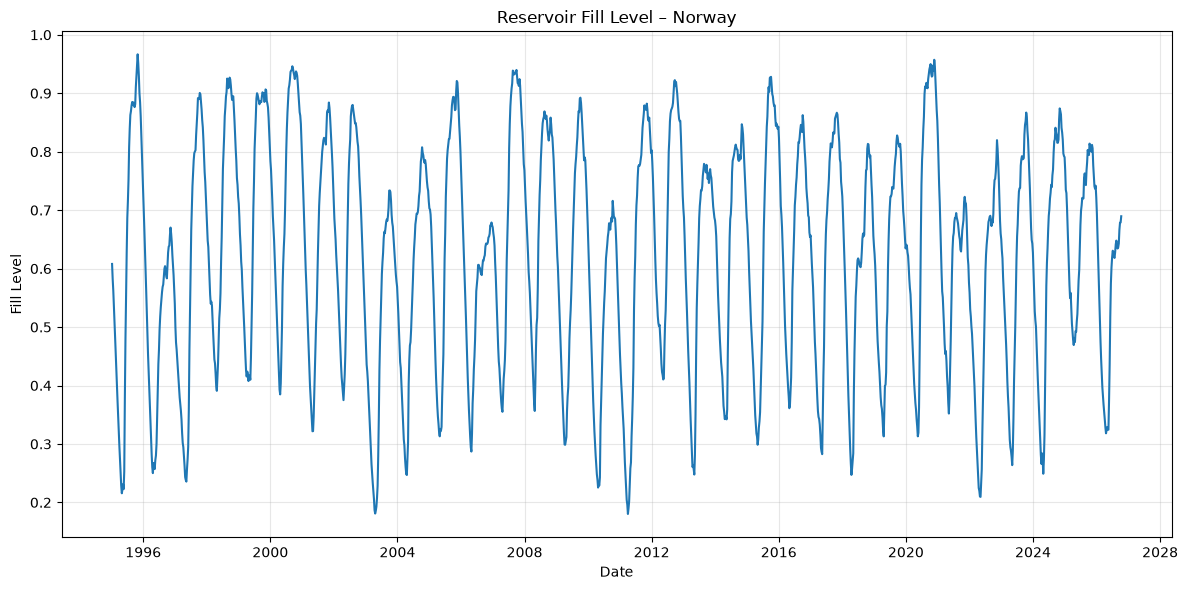

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    national_data["date"],
    national_data["fill_level"],
)

ax.set_title("Reservoir Fill Level – Norway")
ax.set_xlabel("Date")
ax.set_ylabel("Fill Level")
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## 7. MongoDB

The MongoDB Atlas connection is stored securely in a local `.env`
file and is not included in the GitHub repository.

In [14]:
import os

from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv()

mongodb_uri = os.getenv("MONGODB_URI")

client = MongoClient(mongodb_uri)

# Test connection
client.admin.command("ping")

print("MongoDB connection successful.")

MongoDB connection successful.


In [15]:
db = client["ind320"]
collection = db["connection_test"]

test_document = {
    "source": "IND320",
    "message": "MongoDB connection works",
}

result = collection.insert_one(test_document)

print("Inserted document ID:", result.inserted_id)

Inserted document ID: 6ad71cd47ec9a581a41064c4


In [16]:
document = collection.find_one(
    {"message": "MongoDB connection works"}
)

document

{'_id': ObjectId('6ad71cd47ec9a581a41064c4'),
 'source': 'IND320',
 'message': 'MongoDB connection works'}

In [17]:
delete_result = collection.delete_one(
    {"message": "MongoDB connection works"}
)

print("Deleted documents:", delete_result.deleted_count)

Deleted documents: 1


In [18]:
client.close()

## 4. ENTSO-E API

Cross-border physical flow data are retrieved from the ENTSO-E
Transparency Platform Web API. The API security token is stored
locally in a `.env` file and is not included in the GitHub repository.

In [19]:
import os
import requests

from dotenv import load_dotenv

load_dotenv()

ENTSOE_TOKEN = os.getenv("ENTSOE_TOKEN")
ENTSOE_API_URL = "https://web-api.tp.entsoe.eu/api"

NO2 = "10YNO-2--------T"
DE_LU = "10Y1001A1001A82H"

In [20]:
params = {
    "securityToken": ENTSOE_TOKEN,
    "documentType": "A11",
    "out_Domain": NO2,
    "in_Domain": DE_LU,
    "periodStart": "202610010000",
    "periodEnd": "202610020000",
}

response = requests.get(
    ENTSOE_API_URL,
    params=params,
    timeout=30,
)

print("Status code:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))
print(response.text[:500])

Status code: 200
Content type: text/xml
<?xml version="1.0" encoding="utf-8"?>
<Publication_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:0">
  <mRID>35e89282e6324c05b57e5b411c54d14b</mRID>
  <revisionNumber>1</revisionNumber>
  <type>A11</type>
  <sender_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</sender_MarketParticipant.mRID>
  <sender_MarketParticipant.marketRole.type>A32</sender_MarketParticipant.marketRole.type>
  <receiver_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</


In [21]:
import pandas as pd
import xml.etree.ElementTree as ET


def parse_entsoe_physical_flow(xml_text, connection, direction):
    """
    Parse ENTSO-E cross-border physical flow XML into a pandas DataFrame.
    """

    root = ET.fromstring(xml_text)

    # Extract XML namespace
    namespace = {
        "ns": root.tag.split("}")[0].strip("{")
    }

    rows = []

    for time_series in root.findall("ns:TimeSeries", namespace):
        out_domain = time_series.findtext(
            "ns:out_Domain.mRID",
            namespaces=namespace,
        )

        in_domain = time_series.findtext(
            "ns:in_Domain.mRID",
            namespaces=namespace,
        )

        for period in time_series.findall("ns:Period", namespace):
            start = pd.Timestamp(
                period.findtext(
                    "ns:timeInterval/ns:start",
                    namespaces=namespace,
                )
            )

            resolution = period.findtext(
                "ns:resolution",
                namespaces=namespace,
            )

            # Convert ENTSO-E resolution to a time interval
            if resolution.endswith("M"):
                minutes = int(
                    resolution.replace("PT", "").replace("M", "")
                )
            elif resolution.endswith("H"):
                minutes = (
                    int(
                        resolution.replace("PT", "").replace("H", "")
                    )
                    * 60
                )
            else:
                raise ValueError(
                    f"Unsupported resolution: {resolution}"
                )

            for point in period.findall("ns:Point", namespace):
                position = int(
                    point.findtext(
                        "ns:position",
                        namespaces=namespace,
                    )
                )

                quantity_mw = float(
                    point.findtext(
                        "ns:quantity",
                        namespaces=namespace,
                    )
                )

                timestamp = start + pd.Timedelta(
                    minutes=(position - 1) * minutes
                )

                rows.append(
                    {
                        "timestamp": timestamp,
                        "connection": connection,
                        "direction": direction,
                        "out_domain": out_domain,
                        "in_domain": in_domain,
                        "quantity_mw": quantity_mw,
                        "interval_minutes": minutes,
                        "energy_mwh": (
                            quantity_mw * minutes / 60
                        ),
                    }
                )

    return pd.DataFrame(rows)

In [22]:
test_flow_df = parse_entsoe_physical_flow(
    response.text,
    connection="NO2-DE_LU",
    direction="NO2 -> DE-LU",
)

test_flow_df.head()

,timestamp,connection,direction,out_domain,in_domain,quantity_mw,interval_minutes,energy_mwh
0,2026-10-01 00:00:00+00:00,NO2-DE_LU,NO2 -> DE-LU,10YNO-2--------T,10Y1001A1001A82H,1047.52,15,261.88
1,2026-10-01 00:15:00+00:00,NO2-DE_LU,NO2 -> DE-LU,10YNO-2--------T,10Y1001A1001A82H,1043.84,15,260.96
2,2026-10-01 00:30:00+00:00,NO2-DE_LU,NO2 -> DE-LU,10YNO-2--------T,10Y1001A1001A82H,1080.80,15,270.20
3,2026-10-01 00:45:00+00:00,NO2-DE_LU,NO2 -> DE-LU,10YNO-2--------T,10Y1001A1001A82H,1114.56,15,278.64
4,2026-10-01 01:00:00+00:00,NO2-DE_LU,NO2 -> DE-LU,10YNO-2--------T,10Y1001A1001A82H,1226.08,15,306.52


In [23]:
test_flow_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 83 entries, 0 to 82
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype              
---  ------            --------------  -----              
 0   timestamp         83 non-null     datetime64[us, UTC]
 1   connection        83 non-null     str                
 2   direction         83 non-null     str                
 3   out_domain        83 non-null     str                
 4   in_domain         83 non-null     str                
 5   quantity_mw       83 non-null     float64            
 6   interval_minutes  83 non-null     int64              
 7   energy_mwh        83 non-null     float64            
dtypes: datetime64[us, UTC](1), float64(2), int64(1), str(4)
memory usage: 9.6 KB


In [24]:
test_flow_df[
    [
        "timestamp",
        "connection",
        "direction",
        "quantity_mw",
        "energy_mwh",
    ]
].head(10)

,timestamp,connection,direction,quantity_mw,energy_mwh
0,2026-10-01 00:00:00+00:00,NO2-DE_LU,NO2 -> DE-LU,1047.52,261.88
1,2026-10-01 00:15:00+00:00,NO2-DE_LU,NO2 -> DE-LU,1043.84,260.96
2,2026-10-01 00:30:00+00:00,NO2-DE_LU,NO2 -> DE-LU,1080.80,270.20
3,2026-10-01 00:45:00+00:00,NO2-DE_LU,NO2 -> DE-LU,1114.56,278.64
4,2026-10-01 01:00:00+00:00,NO2-DE_LU,NO2 -> DE-LU,1226.08,306.52
5,2026-10-01 01:15:00+00:00,NO2-DE_LU,NO2 -> DE-LU,1245.76,311.44
6,2026-10-01 01:30:00+00:00,NO2-DE_LU,NO2 -> DE-LU,1238.40,309.60
7,2026-10-01 01:45:00+00:00,NO2-DE_LU,NO2 -> DE-LU,1289.92,322.48
8,2026-10-01 02:00:00+00:00,NO2-DE_LU,NO2 -> DE-LU,1301.92,325.48
9,2026-10-01 02:15:00+00:00,NO2-DE_LU,NO2 -> DE-LU,1296.64,324.16


In [25]:
def fetch_entsoe_flow(
    out_domain,
    in_domain,
    period_start,
    period_end,
    connection,
    direction,
):
    """
    Download and parse physical cross-border flow data from ENTSO-E.
    """

    params = {
        "securityToken": ENTSOE_TOKEN,
        "documentType": "A11",
        "out_Domain": out_domain,
        "in_Domain": in_domain,
        "periodStart": period_start.strftime("%Y%m%d%H%M"),
        "periodEnd": period_end.strftime("%Y%m%d%H%M"),
    }

    response = requests.get(
        ENTSOE_API_URL,
        params=params,
        timeout=60,
    )

    response.raise_for_status()

    return parse_entsoe_physical_flow(
        response.text,
        connection=connection,
        direction=direction,
    )

In [26]:
start = pd.Timestamp("2026-10-01", tz="UTC")
end = pd.Timestamp("2026-10-08", tz="UTC")

export_df = fetch_entsoe_flow(
    out_domain=NO2,
    in_domain=DE_LU,
    period_start=start,
    period_end=end,
    connection="NO2-DE_LU",
    direction="Export",
)

import_df = fetch_entsoe_flow(
    out_domain=DE_LU,
    in_domain=NO2,
    period_start=start,
    period_end=end,
    connection="NO2-DE_LU",
    direction="Import",
)

test_connection_df = pd.concat(
    [export_df, import_df],
    ignore_index=True,
)

test_connection_df.head()

,timestamp,connection,direction,out_domain,in_domain,quantity_mw,interval_minutes,energy_mwh
0,2026-10-01 00:00:00+00:00,NO2-DE_LU,Export,10YNO-2--------T,10Y1001A1001A82H,1047.52,15,261.88
1,2026-10-01 00:15:00+00:00,NO2-DE_LU,Export,10YNO-2--------T,10Y1001A1001A82H,1043.84,15,260.96
2,2026-10-01 00:30:00+00:00,NO2-DE_LU,Export,10YNO-2--------T,10Y1001A1001A82H,1080.80,15,270.20
3,2026-10-01 00:45:00+00:00,NO2-DE_LU,Export,10YNO-2--------T,10Y1001A1001A82H,1114.56,15,278.64
4,2026-10-01 01:00:00+00:00,NO2-DE_LU,Export,10YNO-2--------T,10Y1001A1001A82H,1226.08,15,306.52


In [27]:
test_connection_df.groupby("direction").agg(
    observations=("quantity_mw", "size"),
    total_mwh=("energy_mwh", "sum"),
)

,observations,total_mwh
direction,,
Export,496,149676.92000
Import,95,15853.43475


In [28]:
CONNECTIONS = {
    "NO1-SE3": (...),
    "NO2-DK1": (...),
    "NO2-DE_LU": (...),
    "NO2-NL": (...),
    "NO2-GB": (...),
    "NO3-SE2": (...),
    "NO4-SE1": (...),
    "NO4-SE2": (...),
    "NO4-FI": (...),
}

In [29]:
CONNECTIONS = {
    "NO1-SE3": {
        "norway": "10YNO-1--------2",
        "foreign": "10Y1001A1001A46L",
    },
    "NO2-DK1": {
        "norway": "10YNO-2--------T",
        "foreign": "10YDK-1--------W",
    },
    "NO2-DE_LU": {
        "norway": "10YNO-2--------T",
        "foreign": "10Y1001A1001A82H",
    },
    "NO2-NL": {
        "norway": "10YNO-2--------T",
        "foreign": "10YNL----------L",
    },
    "NO2-GB": {
        "norway": "10YNO-2--------T",
        "foreign": "10YGB----------A",
    },
    "NO3-SE2": {
        "norway": "10YNO-3--------J",
        "foreign": "10Y1001A1001A45N",
    },
    "NO4-SE1": {
        "norway": "10YNO-4--------9",
        "foreign": "10Y1001A1001A44P",
    },
    "NO4-SE2": {
        "norway": "10YNO-4--------9",
        "foreign": "10Y1001A1001A45N",
    },
    "NO4-FI": {
        "norway": "10YNO-4--------9",
        "foreign": "10YFI-1--------U",
    },
}

In [30]:
def fetch_connection_two_years(
    connection_name,
    connection_info,
    start_date,
    end_date,
):
    """
    Download both import and export data for one connection.
    Requests are split into periods of at most one year.
    """

    all_frames = []

    period_start = start_date

    while period_start < end_date:
        period_end = min(
            period_start + pd.DateOffset(years=1),
            end_date,
        )

        norway = connection_info["norway"]
        foreign = connection_info["foreign"]

        print(
            f"Downloading {connection_name}: "
            f"{period_start.date()} to {period_end.date()}"
        )

        # Export from Norway
        export_df = fetch_entsoe_flow(
            out_domain=norway,
            in_domain=foreign,
            period_start=period_start,
            period_end=period_end,
            connection=connection_name,
            direction="Export",
        )

        # Import to Norway
        import_df = fetch_entsoe_flow(
            out_domain=foreign,
            in_domain=norway,
            period_start=period_start,
            period_end=period_end,
            connection=connection_name,
            direction="Import",
        )

        all_frames.extend(
            [export_df, import_df]
        )

        period_start = period_end

    return pd.concat(
        all_frames,
        ignore_index=True,
    )

In [31]:
two_year_end = pd.Timestamp(
    "2026-10-20",
    tz="UTC",
)

two_year_start = two_year_end - pd.DateOffset(years=2)

In [32]:
no2_de_two_years = fetch_connection_two_years(
    connection_name="NO2-DE_LU",
    connection_info=CONNECTIONS["NO2-DE_LU"],
    start_date=two_year_start,
    end_date=two_year_end,
)

no2_de_two_years.info()

<class 'pandas.DataFrame'>
RangeIndex: 63918 entries, 0 to 63917
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype              
---  ------            --------------  -----              
 0   timestamp         63918 non-null  datetime64[us, UTC]
 1   connection        63918 non-null  str                
 2   direction         63918 non-null  str                
 3   out_domain        63918 non-null  str                
 4   in_domain         63918 non-null  str                
 5   quantity_mw       63918 non-null  float64            
 6   interval_minutes  63918 non-null  int64              
 7   energy_mwh        63918 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(2), int64(1), str(4)
memory usage: 6.8 MB


In [33]:
no2_de_two_years.groupby("direction").agg(
    observations=("quantity_mw", "size"),
    total_mwh=("energy_mwh", "sum"),
)

,observations,total_mwh
direction,,
Export,47186,1.136287e+07
Import,16732,3.077421e+06


In [34]:
entsoe_df.to_pickle(r"C:\dev\IND320\entsoe_temp.pkl")

NameError: name 'entsoe_df' is not defined

In [ ]:
import pandas as pd

entsoe_df = pd.read_pickle(r"C:\dev\IND320\entsoe_temp.pkl")

In [ ]:
"""
import time

all_connections = []

for connection_name, connection_info in CONNECTIONS.items():
    print(f"\nProcessing {connection_name}...")

    try:
        connection_df = fetch_connection_two_years(
            connection_name=connection_name,
            connection_info=connection_info,
            start_date=two_year_start,
            end_date=two_year_end,
        )

        print(
            f"{connection_name}: "
            f"{len(connection_df):,} observations"
        )

        all_connections.append(connection_df)

        # Small pause between connections
        time.sleep(1)

    except Exception as error:
        print(
            f"Could not download {connection_name}: {error}"
        )
"""


Processing NO1-SE3...
NO1-SE3: 47,323 observations

Processing NO2-DK1...
NO2-DK1: 60,096 observations

Processing NO2-DE_LU...
NO2-DE_LU: 63,918 observations

Processing NO2-NL...
NO2-NL: 37,831 observations

Processing NO2-GB...
NO2-GB: 67,463 observations

Processing NO3-SE2...
NO3-SE2: 47,053 observations

Processing NO4-SE1...
NO4-SE1: 47,533 observations

Processing NO4-SE2...
NO4-SE2: 46,510 observations

Processing NO4-FI...
NO4-FI: 65,552 observations


In [ ]:
entsoe_df = pd.concat(
    all_connections,
    ignore_index=True,
)

entsoe_df = (
    entsoe_df
    .sort_values(
        ["connection", "timestamp", "direction"]
    )
    .reset_index(drop=True)
)

entsoe_df.head()

,timestamp,connection,direction,out_domain,in_domain,quantity_mw,interval_minutes,energy_mwh
0,2024-10-20 00:00:00+00:00,NO1-SE3,Export,10YNO-1--------2,10Y1001A1001A46L,0.0000,60,0.0000
1,2024-10-20 00:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1002.2950,60,1002.2950
2,2024-10-20 01:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1064.2175,60,1064.2175
3,2024-10-20 02:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1084.2900,60,1084.2900
4,2024-10-20 03:00:00+00:00,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1084.1575,60,1084.1575


In [ ]:
entsoe_df.groupby(
    ["connection", "direction"]
).agg(
    observations=("quantity_mw", "size"),
    total_mwh=("energy_mwh", "sum"),
)

observations     total_mwh
connection direction                            
NO1-SE3    Export            12627  3.075436e+06
           Import            34696  1.202813e+07
NO2-DE_LU  Export            47186  1.136287e+07
           Import            16732  3.077421e+06
NO2-DK1    Export            41271  1.388483e+07
           Import            18825  3.981912e+06
NO2-GB     Export            58110  1.747474e+07
           Import             9353  1.826499e+06
NO2-NL     Export            28387  3.465896e+06
           Import             9444  8.132092e+05
NO3-SE2    Export            15039  1.522974e+06
           Import            32014  3.532966e+06
NO4-FI     Export            48681  5.607321e+05
           Import            16871  8.736542e+04
NO4-SE1    Export            31616  3.003656e+06
           Import            15917  1.330112e+06
NO4-SE2    Export            29610  9.583882e+05
           Import            16900  4.289763e+05

In [ ]:
print(
    "Connections:",
    sorted(entsoe_df["connection"].unique())
)

print(
    "Total observations:",
    f"{len(entsoe_df):,}"
)

print(
    "Period:",
    entsoe_df["timestamp"].min(),
    "to",
    entsoe_df["timestamp"].max(),
)

Connections: ['NO1-SE3', 'NO2-DE_LU', 'NO2-DK1', 'NO2-GB', 'NO2-NL', 'NO3-SE2', 'NO4-FI', 'NO4-SE1', 'NO4-SE2']
Total observations: 483,279
Period: 2024-10-20 00:00:00+00:00 to 2026-10-19 23:45:00+00:00


In [ ]:
print(
    "Duplicate rows:",
    entsoe_df.duplicated(
        subset=["connection", "direction", "timestamp"]
    ).sum(),
)

print("\nMissing values:")
print(entsoe_df.isna().sum())

Duplicate rows: 0

Missing values:
timestamp           0
connection          0
direction           0
out_domain          0
in_domain           0
quantity_mw         0
interval_minutes    0
energy_mwh          0
dtype: int64


In [ ]:
spark_input = entsoe_df.copy()

# Cassandra/Spark handles UTC timestamps more predictably
# when pandas timezone information is removed after conversion to UTC.
spark_input["timestamp_utc"] = (
    spark_input["timestamp"]
    .dt.tz_convert("UTC")
    .dt.tz_localize(None)
)

spark_input = spark_input.drop(columns=["timestamp"])

spark_input.head()

,connection,direction,out_domain,in_domain,quantity_mw,interval_minutes,energy_mwh,timestamp_utc
0,NO1-SE3,Export,10YNO-1--------2,10Y1001A1001A46L,0.0000,60,0.0000,2024-10-20 00:00:00
1,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1002.2950,60,1002.2950,2024-10-20 00:00:00
2,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1064.2175,60,1064.2175,2024-10-20 01:00:00
3,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1084.2900,60,1084.2900,2024-10-20 02:00:00
4,NO1-SE3,Import,10Y1001A1001A46L,10YNO-1--------2,1084.1575,60,1084.1575,2024-10-20 03:00:00


In [ ]:
import distutils

print("distutils available")

ModuleNotFoundError: No module named 'distutils'

In [ ]:
from pyspark.sql import functions as F

spark_df = spark.createDataFrame(spark_input)

spark_df = spark_df.select(
    F.col("connection").cast("string"),
    F.col("direction").cast("string"),
    F.col("timestamp_utc").cast("timestamp"),
    F.col("out_domain").cast("string"),
    F.col("in_domain").cast("string"),
    F.col("quantity_mw").cast("double"),
    F.col("interval_minutes").cast("int"),
    F.col("energy_mwh").cast("double"),
)

spark_df.printSchema()

ModuleNotFoundError: No module named 'distutils'